# Ames Housing Regression: Predicting `Year Built`

**Research Question:** How accurately can a machine learning model predict a residential property's original construction year based solely on its current structural materials, layout configuration and quality ratings, with no temporal metadata and no market data in sight?


> **Prerequisite:** run `preprocessing.ipynb` first to generate `preprocessed_data.pkl`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from scipy.stats import uniform

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, GridSearchCV, RandomizedSearchCV

## Data Loading

The preprocessed feature matrices and target variable produced by `preprocessing.ipynb` are loaded from disk for the regression task.

In [2]:
with open('../data/processed/preprocessed_data.pkl', 'rb') as f:
    data = pickle.load(f)

X            = data['X']
y            = data['y']
X_train      = data['X_train']
X_test       = data['X_test']
y_train      = data['y_train']
y_test       = data['y_test']
preprocessor = data['preprocessor']

print(f'X_train : {X_train.shape}  |  X_test : {X_test.shape}')
print(f'y range : {int(y.min())} to {int(y.max())}')

X_train : (2344, 70)  |  X_test : (586, 70)
y range : 1872 to 2010


## Model Selection

Nine regressors are included to cover a broad range of learning strategies: a linear baseline (Linear Regression), a regularised linear model (Ridge), a decision tree, random forest, gradient boosting, XGBoost, support vector regression, k-nearest neighbours and a multi-layer perceptron. Note: Polynomial Regression was replaced with Ridge because applying degree-2 expansion to the 150+ preprocessed features produces an ill-conditioned ~11,000-feature matrix that makes ordinary least squares numerically unstable.

In [3]:
models = {
    'Linear Regression':      LinearRegression(),
    'Ridge Regression':       Ridge(alpha=1.0),
    'Decision Tree':          DecisionTreeRegressor(random_state=42),
    'Random Forest':          RandomForestRegressor(random_state=42),
    'Gradient Boosting':      GradientBoostingRegressor(random_state=42),
    'XGBoost':                XGBRegressor(random_state=42),
    'Support Vector Regressor': SVR(),
    'K-Nearest Neighbors':    KNeighborsRegressor(n_neighbors=5),
    'Neural Network':         MLPRegressor(random_state=42, max_iter=2000),
}

### Evaluation Function

A helper function computes MAE, MSE, RMSE and R² for a given set of predictions, providing a single, reusable interface used throughout the model comparison and tuning stages below.

In [4]:
def evaluation_matrix(model_name, y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_true, y_pred)
    return {
        'Model': model_name,
        'MAE':   round(mae,  4),
        'MSE':   round(mse,  4),
        'RMSE':  round(rmse, 4),
        'R2':    round(r2,   4),
    }

## Training & Evaluation

In [5]:
trained_models = {}
eval_matrix    = []

for model_name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        # clone() gives each model a fresh, unfitted copy so that fitting one
        # model in this loop cannot affect the parameters used by another.
        ('model', clone(model)),
    ])
    pipeline.fit(X_train, y_train)
    # Split transform and predict so the same transformed test matrix can be
    # reused below (Actual vs Predicted plot) without repeating the ColumnTransformer step.
    X_test_t = pipeline[:-1].transform(X_test)
    y_pred   = pipeline[-1].predict(X_test_t)
    trained_models[model_name] = y_pred
    eval_matrix.append(evaluation_matrix(model_name, y_test, y_pred))

print('Training complete.')

Training complete.


The resulting metrics for all nine regressors are collected into a single table for direct comparison.

In [6]:
eval_matrix_df = pd.DataFrame(eval_matrix)
eval_matrix_df

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,8.0033,120.8650,10.9939,0.8622
1,Ridge Regression,8.0044,119.8610,10.9481,0.8633
2,Decision Tree,6.8020,149.2321,12.2161,0.8299
3,Random Forest,4.8384,82.4430,9.0798,0.9060
4,Gradient Boosting,5.5499,77.8845,8.8252,0.9112
5,XGBoost,5.4257,86.9339,9.3238,0.9009
6,Support Vector Regressor,8.4758,171.2937,13.0879,0.8047
7,K-Nearest Neighbors,5.4549,91.3640,9.5585,0.8958
8,Neural Network,6.7705,110.9045,10.5311,0.8736


The best-performing model for each metric is then identified explicitly, since no single regressor necessarily dominates across all four criteria.

In [7]:
best_mae_idx  = eval_matrix_df['MAE'].idxmin()
best_mse_idx  = eval_matrix_df['MSE'].idxmin()
best_rmse_idx = eval_matrix_df['RMSE'].idxmin()
best_r2_idx   = eval_matrix_df['R2'].idxmax()

best_row = {
    'Model': 'Best Model',
    'MAE':   eval_matrix_df.loc[best_mae_idx,  'Model'],
    'MSE':   eval_matrix_df.loc[best_mse_idx,  'Model'],
    'RMSE':  eval_matrix_df.loc[best_rmse_idx, 'Model'],
    'R2':    eval_matrix_df.loc[best_r2_idx,   'Model'],
}
pd.concat([eval_matrix_df, pd.DataFrame([best_row])], ignore_index=True)

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,8.0033,120.865,10.9939,0.8622
1,Ridge Regression,8.0044,119.861,10.9481,0.8633
2,Decision Tree,6.802,149.2321,12.2161,0.8299
3,Random Forest,4.8384,82.443,9.0798,0.906
4,Gradient Boosting,5.5499,77.8845,8.8252,0.9112
5,XGBoost,5.4257,86.9339,9.3238,0.9009
6,Support Vector Regressor,8.4758,171.2937,13.0879,0.8047
7,K-Nearest Neighbors,5.4549,91.364,9.5585,0.8958
8,Neural Network,6.7705,110.9045,10.5311,0.8736
9,Best Model,Random Forest,Gradient Boosting,Gradient Boosting,Gradient Boosting


### Visual Comparison of Regression Models

The RMSE and R² columns from the table above are plotted side by side below, since the relative size of the gap between the tree-based ensembles and the linear/kernel baselines is easier to judge visually than from the table alone.

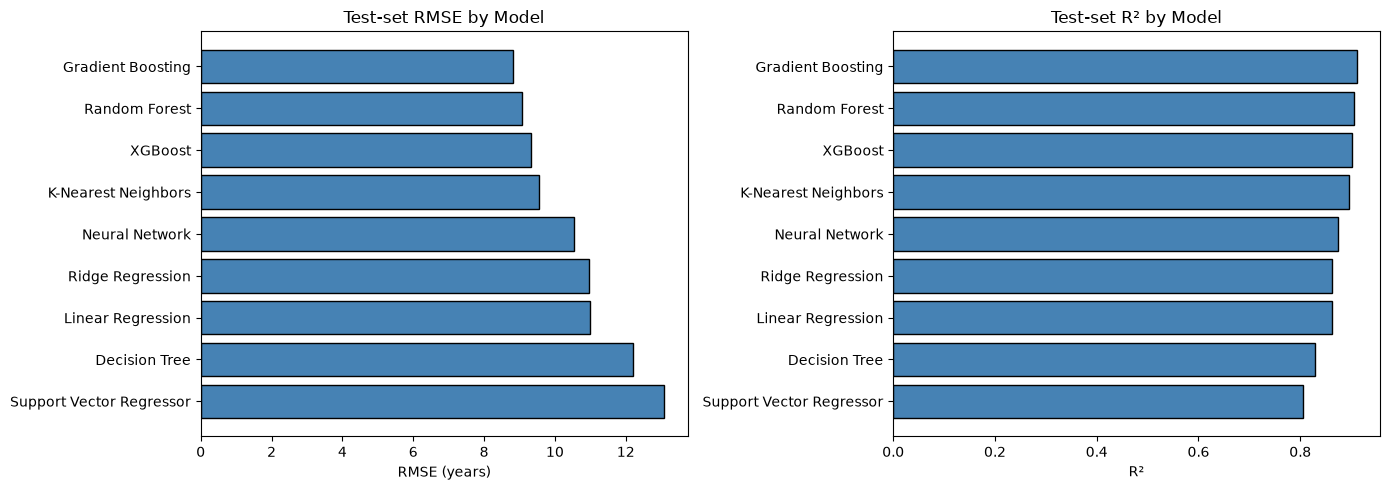

In [8]:
plot_order = eval_matrix_df.sort_values('RMSE', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(plot_order['Model'], plot_order['RMSE'], color='steelblue', edgecolor='black')
axes[0].set_xlabel('RMSE (years)')
axes[0].set_title('Test-set RMSE by Model')

axes[1].barh(plot_order['Model'], plot_order['R2'], color='steelblue', edgecolor='black')
axes[1].set_xlabel('R\u00b2')
axes[1].set_title('Test-set R\u00b2 by Model')

plt.tight_layout()
plt.show()

## Cross-Validation (5-Fold)

In [9]:
cv_results = []
cv_rmse_mean, cv_rmse_std = [], []  # retained separately (as floats) for the CV plot below
for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    # neg_mean_squared_error is used because scikit-learn's scoring convention
    # requires higher values to indicate better performance; negating MSE
    # before the square root recovers RMSE in its usual (positive) units.
    # Restricted to the training fold only, so the held-out test set used for
    # the final evaluation above is never seen during this stability check.
    scores      = cross_val_score(pipe, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
    rmse_scores = np.sqrt(-scores)
    cv_rmse_mean.append(rmse_scores.mean())
    cv_rmse_std.append(rmse_scores.std())
    cv_results.append({
        'Model':         name,
        'CV RMSE mean':  f'{rmse_scores.mean():.4f}',
        'CV RMSE std':   f'+/- {rmse_scores.std():.4f}',
    })

cv_results_df = pd.DataFrame(cv_results)
cv_results_df


,Model,CV RMSE mean,CV RMSE std
0,Linear Regression,11.3053,+/- 0.6485
1,Ridge Regression,11.2238,+/- 0.6883
2,Decision Tree,12.9985,+/- 0.7801
3,Random Forest,9.6478,+/- 0.5225
4,Gradient Boosting,9.7327,+/- 0.6140
5,XGBoost,9.5799,+/- 0.9662
6,Support Vector Regressor,15.4266,+/- 0.9851
7,K-Nearest Neighbors,10.8073,+/- 0.9653
8,Neural Network,14.8494,+/- 1.9912


The mean $\pm$ standard deviation RMSE from the cross-validation above is plotted below, to compare model stability across folds visually rather than only from the table.

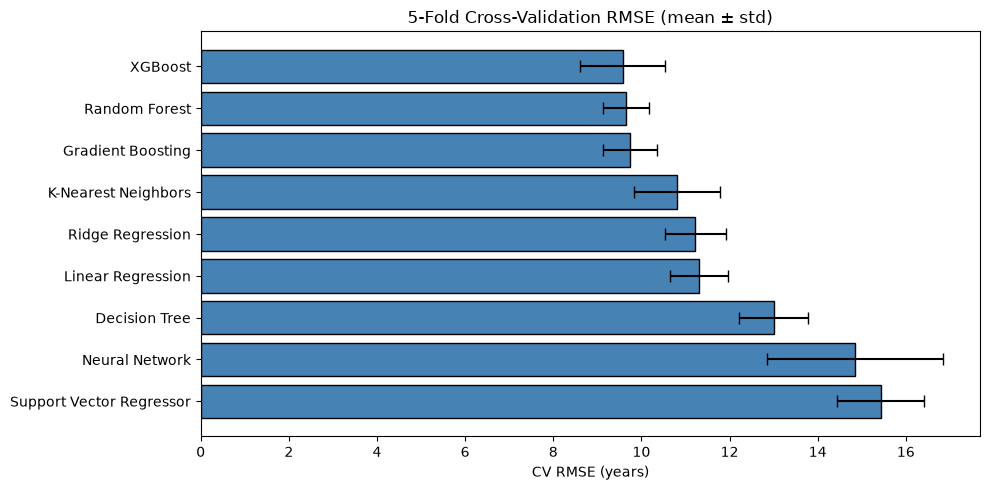

In [10]:
order       = np.argsort(cv_rmse_mean)[::-1]
model_names = list(models.keys())

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh([model_names[i] for i in order],
        [cv_rmse_mean[i] for i in order],
        xerr=[cv_rmse_std[i] for i in order],
        color='steelblue', edgecolor='black', capsize=4)
ax.set_xlabel('CV RMSE (years)')
ax.set_title('5-Fold Cross-Validation RMSE (mean \u00b1 std)')
plt.tight_layout()
plt.show()

## Actual vs Predicted Construction Year

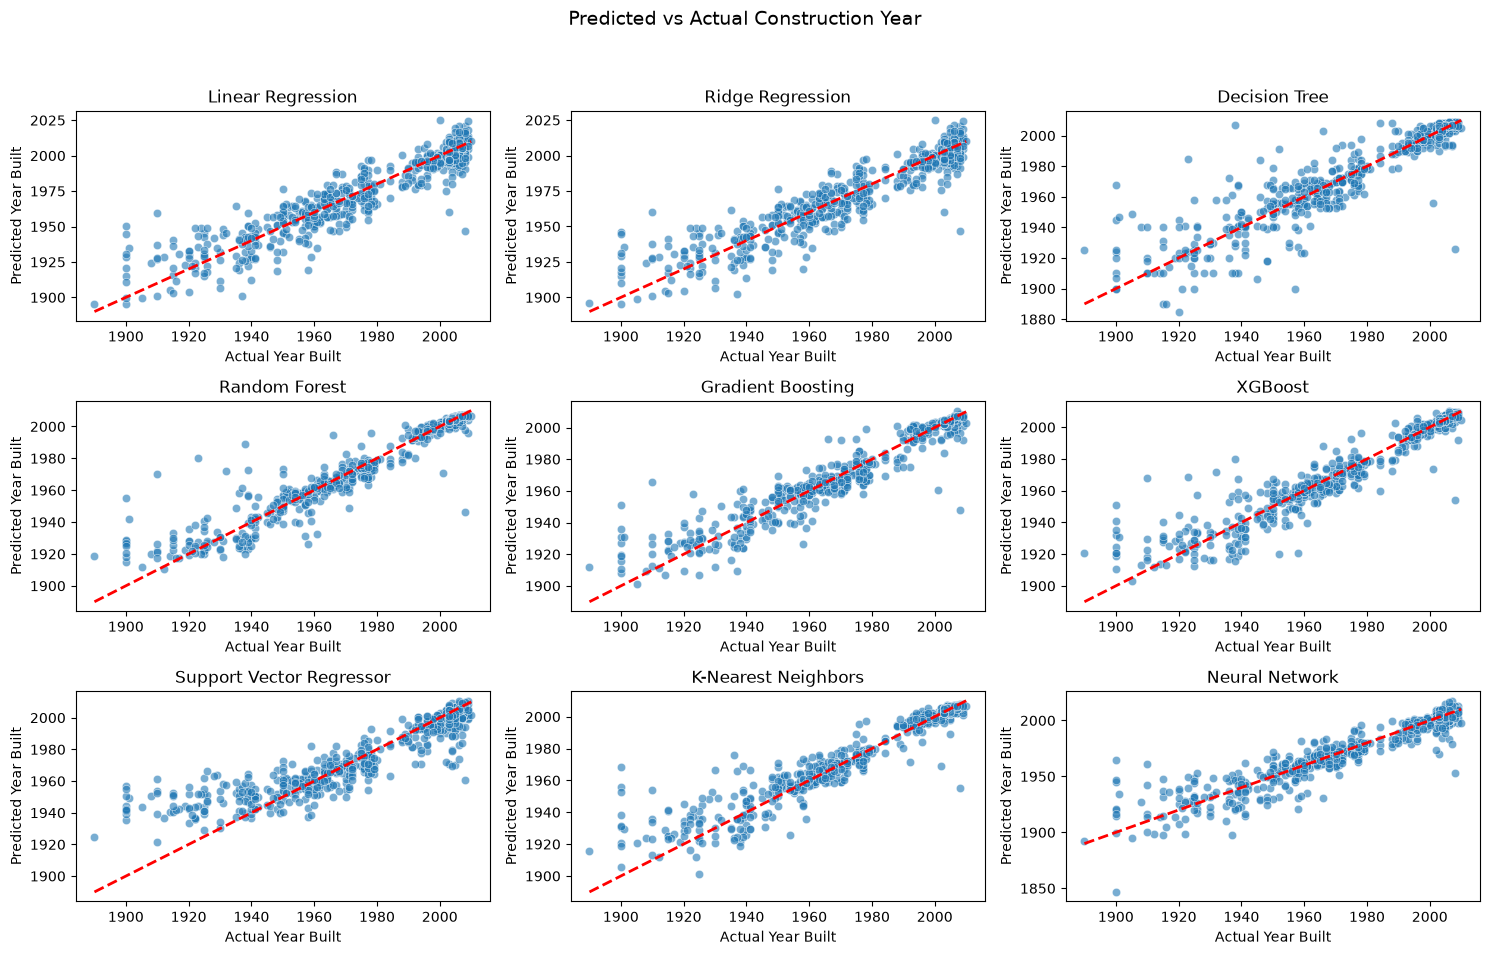

In [11]:
plt.figure(figsize=(15, 10))
plt.suptitle('Predicted vs Actual Construction Year', fontsize=14)

for i, (name, y_pred) in enumerate(trained_models.items(), 1):
    plt.subplot(3, 3, i)
    sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'r--', lw=2)
    plt.xlabel('Actual Year Built')
    plt.ylabel('Predicted Year Built')
    plt.title(name)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### Predicted vs Actual: Best-Performing Models

The panels above are repeated below for only the four strongest regressors (Random Forest, Gradient Boosting, XGBoost and Ridge Regression as the linear baseline), with RMSE and R² annotated in each title for direct comparison against the perfect-prediction diagonal.

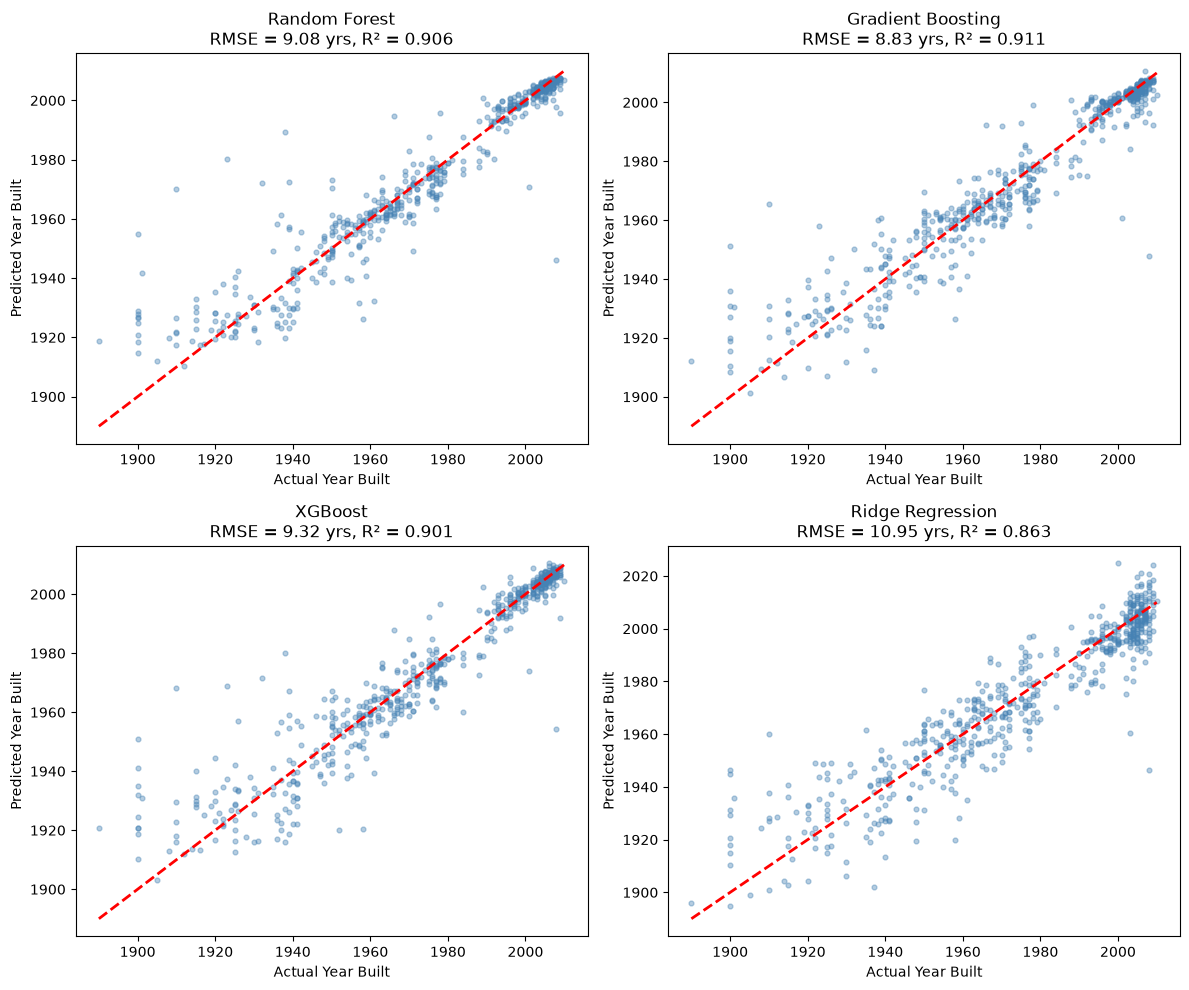

In [12]:
top4_models = {
    'Random Forest':     RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'XGBoost':           XGBRegressor(random_state=42),
    'Ridge Regression':  Ridge(alpha=1.0),
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()
for ax, (name, model) in zip(axes, top4_models.items()):
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', clone(model))])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    rmse   = np.sqrt(mean_squared_error(y_test, y_pred))
    r2     = r2_score(y_test, y_pred)

    ax.scatter(y_test, y_pred, alpha=0.4, s=12, color='steelblue')
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    ax.set_xlabel('Actual Year Built')
    ax.set_ylabel('Predicted Year Built')
    ax.set_title(f'{name}\nRMSE = {rmse:.2f} yrs, R\u00b2 = {r2:.3f}')

plt.tight_layout()
plt.show()

## Feature Importance (Default Random Forest and XGBoost)

Mean-decrease-in-impurity feature importance is extracted from the two best-performing default models to check which predictors they actually rely on. This is a measure of predictive contribution within these specific models, not a causal effect, and it is reported only for the two models for which it is cheap and standard to compute (`feature_importances_`).


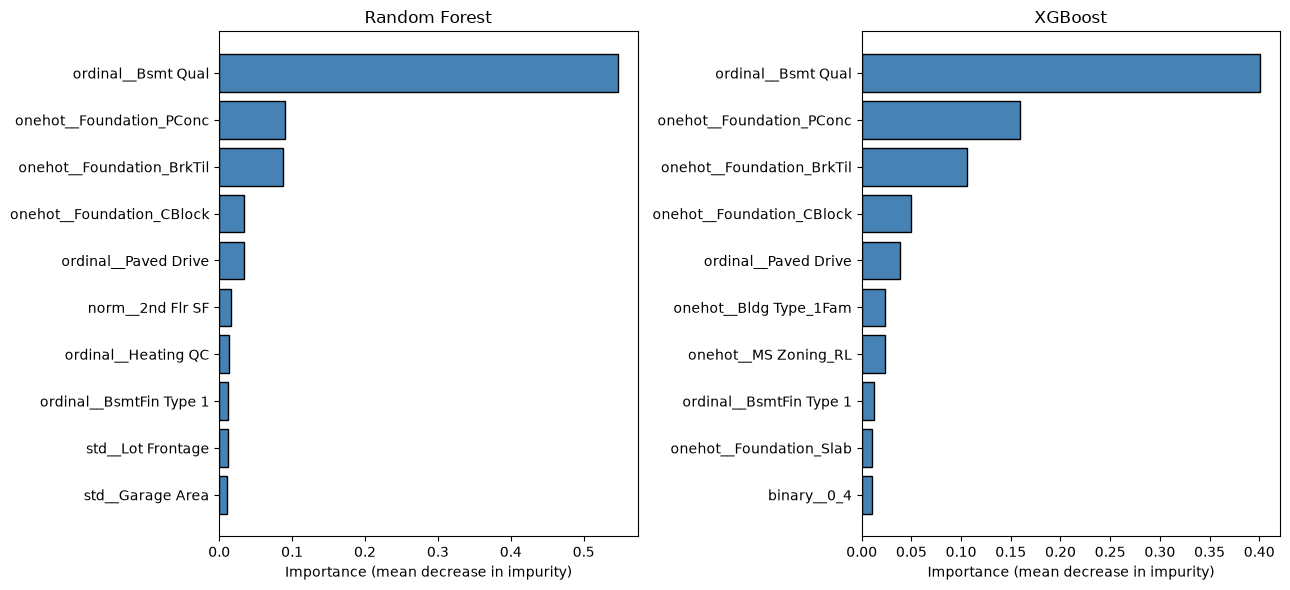

Random Forest -- top 3 features:
  ordinal__Bsmt Qual             0.5465
  onehot__Foundation_PConc       0.0899
  onehot__Foundation_BrkTil      0.0869

XGBoost -- top 3 features:
  ordinal__Bsmt Qual             0.4008
  onehot__Foundation_PConc       0.1593
  onehot__Foundation_BrkTil      0.1058



In [13]:
top_models_fi = {
    'Random Forest': RandomForestRegressor(random_state=42),
    'XGBoost':       XGBRegressor(random_state=42),
}
fitted_fi = {}
for name, model in top_models_fi.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', clone(model))])
    pipe.fit(X_train, y_train)
    fitted_fi[name] = pipe

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, (name, pipe) in zip(axes, fitted_fi.items()):
    feat_names  = pipe.named_steps['preprocessor'].get_feature_names_out()
    importances = pipe.named_steps['model'].feature_importances_
    top_idx     = np.argsort(importances)[-10:]
    ax.barh(range(len(top_idx)), importances[top_idx], color='steelblue', edgecolor='black')
    ax.set_yticks(range(len(top_idx)))
    ax.set_yticklabels([feat_names[i] for i in top_idx])
    ax.set_xlabel('Importance (mean decrease in impurity)')
    ax.set_title(name)
plt.tight_layout()
plt.show()

for name, pipe in fitted_fi.items():
    feat_names  = pipe.named_steps['preprocessor'].get_feature_names_out()
    importances = pipe.named_steps['model'].feature_importances_
    top3 = np.argsort(importances)[::-1][:3]
    print(f'{name} -- top 3 features:')
    for i in top3:
        print(f'  {feat_names[i]:30s} {importances[i]:.4f}')
    print()


## Hyperparameter Tuning

Top 4 performers tuned with cross-validated search:
- **Random Forest** & **XGBoost** → `RandomizedSearchCV` (large grid)
- **Gradient Boosting** & **SVR** → `GridSearchCV`

In [14]:
param_grids = {
    'Random Forest': {
        'model__n_estimators':      [50, 100, 200],
        'model__max_depth':         [None, 10, 20, 30],
        'model__min_samples_split': [2, 5, 10],
        'model__min_samples_leaf':  [1, 2, 4],
    },
    'Gradient Boosting': {
        'model__n_estimators':  [50, 100, 200],
        'model__learning_rate': [0.01, 0.1, 0.2],
        'model__max_depth':     [3, 5, 7],
    },
    'XGBoost': {
        'model__n_estimators':  [50, 100, 200],
        'model__learning_rate': uniform(0.01, 0.3),
        'model__max_depth':     [3, 5, 7],
    },
    'Support Vector Regressor': {
        'model__kernel': ['linear', 'rbf'],
        'model__C':      [0.1, 1, 10],
        'model__gamma':  ['scale', 'auto'],
    },
}

Based on the initial comparison, the four best-performing regressors are carried forward for hyperparameter search; the remaining models are not tuned further given their comparatively weaker baseline performance.

In [15]:
tune_models = {
    'Random Forest':            RandomForestRegressor(random_state=42),
    'Gradient Boosting':        GradientBoostingRegressor(random_state=42),
    'XGBoost':                  XGBRegressor(random_state=42),
    'Support Vector Regressor': SVR(),
}
best_models = {}

Each selected model is tuned in turn, using randomised search for Random Forest and XGBoost given their larger parameter spaces, and exhaustive grid search for Gradient Boosting and the Support Vector Regressor.

In [16]:
for name, model in tune_models.items():
    print(f'Tuning {name}...')
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])

    # RandomizedSearchCV samples a fixed number of parameter combinations
    # (n_iter=10) rather than the full grid, which is preferable for Random
    # Forest and XGBoost given their larger parameter spaces here.
    if name in ['Random Forest', 'XGBoost']:
        search = RandomizedSearchCV(
            pipe, param_distributions=param_grids[name],
            n_iter=10, cv=5, scoring='neg_mean_squared_error',
            n_jobs=-1, random_state=42,
        )
    else:
        search = GridSearchCV(
            pipe, param_grid=param_grids[name],
            cv=5, scoring='neg_mean_squared_error', n_jobs=-1,
        )

    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    print(f'  Best params : {search.best_params_}')
    print(f'  Best CV RMSE: {np.sqrt(-search.best_score_):.4f}')
    print()

Tuning Random Forest...
  Best params : {'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_depth': 30}
  Best CV RMSE: 9.6100

Tuning Gradient Boosting...
  Best params : {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 200}
  Best CV RMSE: 9.2183

Tuning XGBoost...
  Best params : {'model__learning_rate': np.float64(0.13958350559263474), 'model__max_depth': 3, 'model__n_estimators': 200}
  Best CV RMSE: 9.2135

Tuning Support Vector Regressor...
  Best params : {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
  Best CV RMSE: 10.6047



## Final Evaluation: Tuned Models

In [17]:
eval_matrix = []
for name, model in best_models.items():
    y_pred = model.predict(X_test)
    eval_matrix.append(evaluation_matrix(name, y_test, y_pred))

eval_matrix_df = pd.DataFrame(eval_matrix)
eval_matrix_df

,Model,MAE,MSE,RMSE,R2
0,Random Forest,4.8594,83.0754,9.1146,0.9053
1,Gradient Boosting,5.0218,74.0073,8.6027,0.9156
2,XGBoost,5.2543,70.5117,8.3971,0.9196
3,Support Vector Regressor,6.2009,91.1612,9.5478,0.8961


## Results & Discussion

Gradient Boosting achieves the lowest default test-set RMSE (8.83 years, R² = 0.911), with Random Forest (9.08, R² = 0.906) and XGBoost (9.32, R² = 0.901) close behind. Tuning reshuffles this ranking: XGBoost improves the most and becomes the strongest model overall (RMSE = 8.40, R² = 0.920), ahead of Gradient Boosting (8.60) and Random Forest, which is essentially unchanged by tuning (9.11). The gaps between the three ensembles are small relative to their cross-validation standard deviations (roughly 0.5-1.0 RMSE years), so this ranking should be read as indicative rather than statistically decisive.

The linear models (Linear Regression, Ridge) plateau at R² ≈ 0.86 regardless of regularisation strength, roughly 5-6 percentage points behind the tree-based ensembles. Since Ridge's regularisation does not close this gap, the shortfall is better explained by non-linearity in the relationship between physical attributes and construction year (e.g. step changes associated with building-code revisions) than by overfitting or multicollinearity.

The Support Vector Regressor underperforms its ensemble counterparts even after tuning (RMSE improves from 13.09 to 9.55 years, still the weakest of the four tuned models), which points to the RBF kernel's bandwidth being difficult to match to this feature space rather than a fundamental unsuitability of margin-based methods for the task.

The Neural Network's cross-validation RMSE (14.85 ± 1.99 years, computed on the training fold only) is both higher and more variable than any tree-based model, despite a comparatively better single-split test RMSE (10.53 years). This gap between the CV and hold-out estimates indicates the default MLP architecture is sensitive to which rows fall into the training fold, and a single train/test split alone would have overstated its reliability.